# Week 3 · Part A — Rebuild nine charts, then take them apart

All data in `data/` is **synthetic**, generated for CDB601220. Each case below follows the same four steps:
**1. Rebuild** the published chart from its recipe and hit the self-check number →
**2. Conclusion + decoy** (the objection I thought of first, and why the data rules it out) →
**3. Mechanism** (named precisely, with the number that proves it) → **4. Redesign** (the honest chart, plotted).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.insert(0, str(Path.cwd()))
from vizlib import PALETTE, MARKERS, style_defaults

style_defaults(dpi=100)
C3 = PALETTE["series"]                       # blue, vermilion, green (Okabe-Ito subset)
BLUE, VERM, GREEN, GREY, INK = C3[0], C3[1], C3[2], PALETTE["muted"], PALETTE["ink"]
DATA, FIG = Path("data"), Path("figs")
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)

def finish(fig, name, note="synthetic data generated for CDB601220"):
    fig.text(0.01, -0.02, note, fontsize=7, color=PALETTE["ink_soft"], ha="left", va="top")
    fig.savefig(FIG / name, dpi=300, bbox_inches="tight", facecolor="white")   # save BEFORE show
    plt.show()

---
## Case 1 · "Premium-certified helmets have 2.5× the head-injury rate"
### 1 · Rebuild

              head_injuries  trips  per_1000
helmet_grade                                
Standard                129  60000      2.15
Premium                 216  40000      5.40


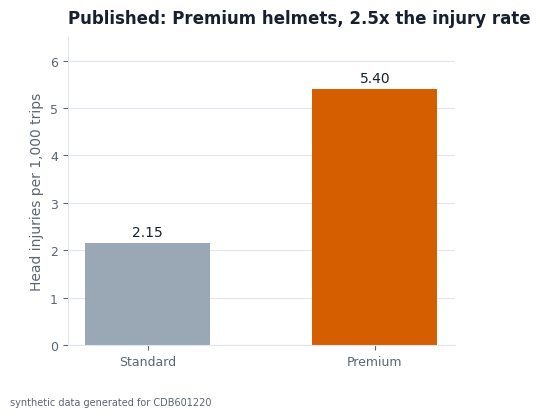

In [2]:
d1 = pd.read_csv(DATA / "case01_helmet_rickshaw.csv")
g1 = d1.groupby("helmet_grade")[["head_injuries", "trips"]].sum().loc[["Standard", "Premium"]]
g1["per_1000"] = g1.head_injuries / g1.trips * 1000
print(g1.round(2))
assert round(g1.loc["Standard", "per_1000"], 2) == 2.15 and round(g1.loc["Premium", "per_1000"], 2) == 5.40   # self-check

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(g1.index, g1.per_1000, color=[GREY, VERM], width=0.55)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_ylim(0, 6.5)                                  # y from zero, as the recipe says
ax.set_ylabel("Head injuries per 1,000 trips")
ax.set_title("Published: Premium helmets, 2.5x the injury rate")
ax.grid(axis="x", visible=False)
finish(fig, "A1_rebuild.png")

### 2 · Conclusion and decoy
**Conclusion the chart invites:** premium-certified helmets are *worse* than standard ones (5.40 vs 2.15 per 1,000 trips).

**Decoy:** "Premium riders must be riskier — less experienced or more reckless." The file lets me test that directly.

In [3]:
print("Mean experience (months) by grade:")
print(d1.groupby("helmet_grade").months_experience.mean().round(1))
t = stats.ttest_ind(d1[d1.helmet_grade == "Premium"].months_experience,
                    d1[d1.helmet_grade == "Standard"].months_experience, equal_var=False)
print(f"Welch t-test on experience: p = {t.pvalue:.2f}")

Mean experience (months) by grade:
helmet_grade
Premium     31.4
Standard    31.5
Name: months_experience, dtype: float64
Welch t-test on experience: p = 0.94


**Why the decoy fails:** the two groups have essentially the same experience (≈ 31.4 vs 31.5 months, p ≈ 0.9), so experience cannot explain the gap.
(`avg_speed_kph` *does* differ a lot between grades — but speed is a property of the road, which is the real story below.)

### 3 · Mechanism — a third variable that reverses the comparison (Simpson's paradox)

In [4]:
mix = pd.crosstab(d1.helmet_grade, d1.road_type, values=d1.trips, aggfunc="sum", normalize="index").loc[["Standard", "Premium"]]
print("Share of each grade's TRIPS by road type:"); print((mix * 100).round(1))

g1r = d1.groupby(["road_type", "helmet_grade"])[["head_injuries", "trips"]].sum()
g1r["per_1000"] = g1r.head_injuries / g1r.trips * 1000
rate = g1r.per_1000.unstack()[["Standard", "Premium"]].loc[["Motorway", "City arterial", "Inner-city lanes"]]
print("\nInjuries per 1,000 trips, within each road type:"); print(rate.round(2))

# direct standardisation: give both grades the SAME road mix (the pooled trip mix)
w = d1.groupby("road_type").trips.sum() / d1.trips.sum()
std = {gr: float((rate[gr] * w.reindex(rate.index)).sum()) for gr in ["Standard", "Premium"]}
print("\nRate if both grades rode the same pooled road mix:", {k: round(v, 2) for k, v in std.items()})

Share of each grade's TRIPS by road type:
road_type     City arterial  Inner-city lanes  Motorway
helmet_grade                                           
Standard               33.3              63.3       3.3
Premium                12.5               2.5      85.0

Injuries per 1,000 trips, within each road type:
helmet_grade      Standard  Premium
road_type                          
Motorway              8.00      6.0
City arterial         3.00      2.2
Inner-city lanes      1.39      1.0

Rate if both grades rode the same pooled road mix: {'Standard': 4.17, 'Premium': 3.1}


**Mechanism:** *road type* is a third variable that sits on both sides. **85% of Premium trips are on the motorway, against 3.3% of Standard trips**,
and the motorway is where almost everyone gets hurt (6–8 per 1,000 vs 1–3 elsewhere). Inside every single road type the Premium helmet has the **lower** rate
(motorway 6.00 vs 8.00; city arterial 2.20 vs 3.00; inner-city lanes 1.00 vs 1.39). Give both grades the same road mix (the pooled trip mix) and Premium is **3.10** vs Standard **4.17** per 1,000 — the sign flips: Premium is ≈ 26% *lower*.
The pooled bar compares *where people ride*, not *what they wear*.

### 4 · Redesign

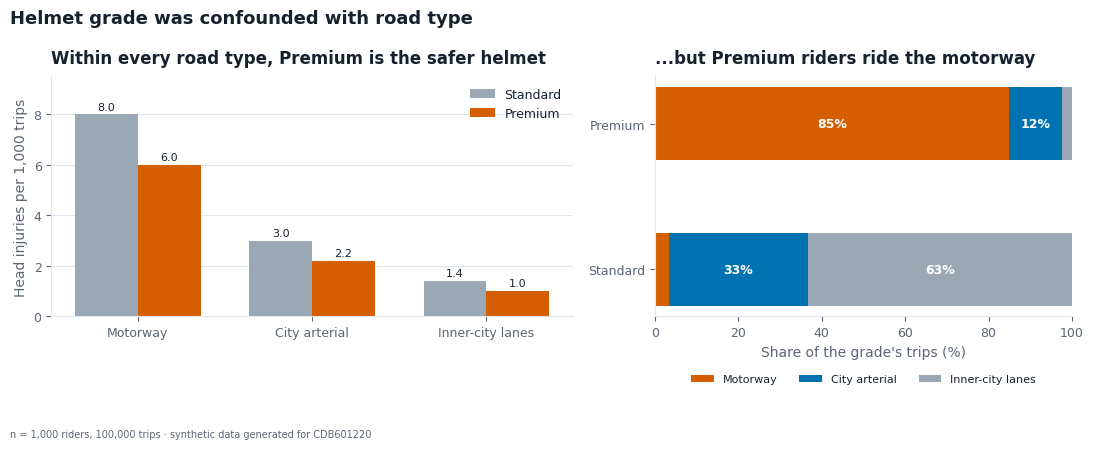

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
x = np.arange(3); wd = 0.36
b1 = a.bar(x - wd/2, rate["Standard"], wd, color=GREY, label="Standard")
b2 = a.bar(x + wd/2, rate["Premium"], wd, color=VERM, label="Premium")
a.bar_label(b1, fmt="%.1f", padding=2, fontsize=8); a.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)
a.set_xticks(x, rate.index); a.set_ylim(0, 9.5); a.grid(axis="x", visible=False)
a.set_ylabel("Head injuries per 1,000 trips"); a.legend(title=None)
a.set_title("Within every road type, Premium is the safer helmet")

m = (mix * 100)[["Motorway", "City arterial", "Inner-city lanes"]]
left = np.zeros(2)
for col, colr in zip(m.columns, [VERM, BLUE, GREY]):
    b.barh(m.index, m[col], left=left, color=colr, label=col, height=0.5)
    for i, v in enumerate(m[col]):
        if v > 6: b.text(left[i] + v/2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += m[col].values
b.set_xlim(0, 100); b.set_xlabel("Share of the grade's trips (%)"); b.grid(False)
b.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
b.set_title("...but Premium riders ride the motorway")
fig.suptitle("Helmet grade was confounded with road type", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
finish(fig, "A1_redesign.png", "n = 1,000 riders, 100,000 trips · synthetic data generated for CDB601220")

---
## Case 2 · "Canteen chai sales predict quiz failures"
### 1 · Rebuild

Pearson r = 0.98


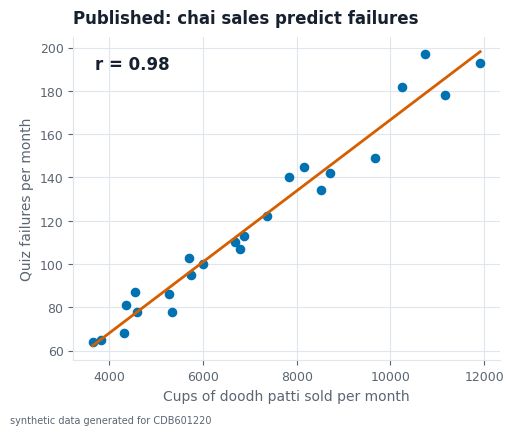

In [6]:
d2 = pd.read_csv(DATA / "case02_chai_quizzes.csv")
r2 = d2.cups_doodh_patti_sold.corr(d2.quiz_failures)
slope, icpt = np.polyfit(d2.cups_doodh_patti_sold, d2.quiz_failures, 1)
print(f"Pearson r = {r2:.2f}")
assert round(r2, 2) == 0.98

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(d2.cups_doodh_patti_sold, d2.quiz_failures, color=BLUE, s=35)
xs = np.linspace(d2.cups_doodh_patti_sold.min(), d2.cups_doodh_patti_sold.max(), 50)
ax.plot(xs, slope * xs + icpt, color=VERM)
ax.text(0.05, 0.9, f"r = {r2:.2f}", transform=ax.transAxes, fontsize=12, fontweight="bold")
ax.set_xlabel("Cups of doodh patti sold per month"); ax.set_ylabel("Quiz failures per month")
ax.set_title("Published: chai sales predict failures")
finish(fig, "A2_rebuild.png")

### 2 · Conclusion and decoy
**Conclusion the chart invites:** more chai → more failed quizzes (r = 0.98), so cut chai (or use it as a failure early-warning).

**Decoy:** "Exam stress drives both — students drink more chai *and* fail more in exam months." Test it with `is_exam_month`.

In [7]:
print(d2.groupby("is_exam_month")[["cups_doodh_patti_sold", "quiz_failures"]].mean().round(0))
print("\nr(is_exam_month, cups)     =", round(d2.is_exam_month.corr(d2.cups_doodh_patti_sold), 2))
print("r(is_exam_month, failures) =", round(d2.is_exam_month.corr(d2.quiz_failures), 2))

               cups_doodh_patti_sold  quiz_failures
is_exam_month                                      
0                             6902.0          111.0
1                             7195.0          129.0

r(is_exam_month, cups)     = 0.06
r(is_exam_month, failures) = 0.21


**Why the decoy fails as the main explanation:** exam months barely move chai (≈ 7,195 vs 6,902 cups, r = 0.06), so exam stress cannot be what links chai to failures.
(Exam months do lift failures a little — 129 vs 111 — a small real effect, but on the failure side only.)

### 3 · Mechanism — one shared driver: head-count

In [8]:
print("r(enrolled, cups)     =", round(d2.students_enrolled.corr(d2.cups_doodh_patti_sold), 3))
print("r(enrolled, failures) =", round(d2.students_enrolled.corr(d2.quiz_failures), 3))
d2["cups_per_student"] = d2.cups_doodh_patti_sold / d2.students_enrolled
d2["failures_per_100"] = d2.quiz_failures / d2.students_enrolled * 100
print("\nenrolment grew", f"{d2.students_enrolled.iloc[0]:,} -> {d2.students_enrolled.iloc[-1]:,}  (x{d2.students_enrolled.iloc[-1]/d2.students_enrolled.iloc[0]:.2f})")
print("failures per 100 students: mean %.2f, min %.2f, max %.2f" % (d2.failures_per_100.mean(), d2.failures_per_100.min(), d2.failures_per_100.max()))
print("r(enrolled, failure RATE) =", round(d2.students_enrolled.corr(d2.failures_per_100), 2))
rr = stats.pearsonr(d2.cups_per_student, d2.failures_per_100)
print(f"per-student chai vs failure rate: r = {rr.statistic:.2f}, p = {rr.pvalue:.2f}, n = 24")

r(enrolled, cups)     = 0.997
r(enrolled, failures) = 0.977

enrolment grew 1,765 -> 5,406  (x3.06)
failures per 100 students: mean 3.56, min 3.22, max 4.03
r(enrolled, failure RATE) = 0.02
per-student chai vs failure rate: r = 0.29, p = 0.16, n = 24


**Mechanism:** *enrolment growth*. The enrolled head-count correlates **0.997** with cups sold and **0.98** with failures — both are **counts that scale with the number of students**
(enrolment grew from 1,765 to 5,406 — about 3×). Divide by head-count and the story disappears: the failure *rate* is flat around **3.5 per 100 students**
(r with enrolment = 0.02), and per-student chai vs failure rate is only r ≈ 0.29 (p ≈ 0.16, n = 24 — not distinguishable from noise).
A common trend in two raw counts is arithmetic, not a relationship between chai and learning.

### 4 · Redesign — both series indexed to one base, and the rate per student

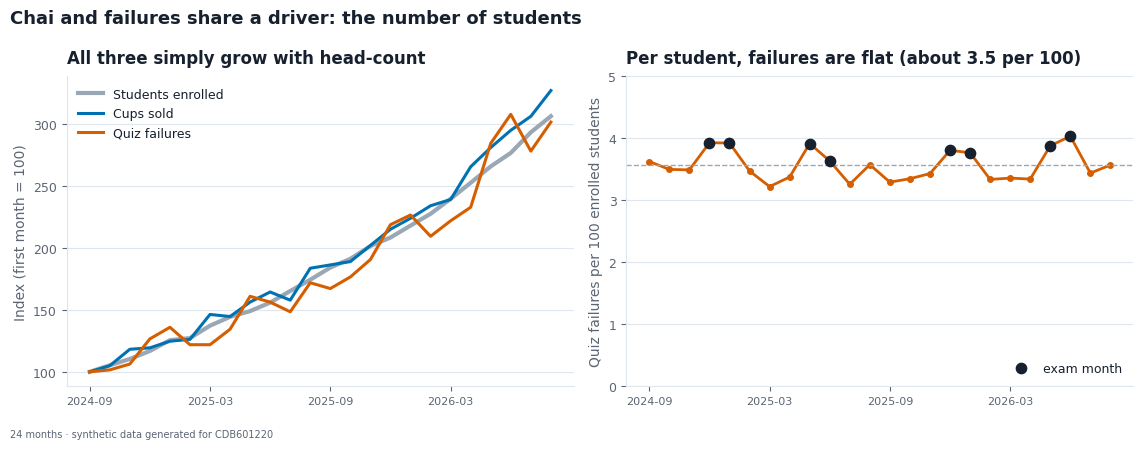

In [9]:
idx = d2.set_index("month")[["students_enrolled", "cups_doodh_patti_sold", "quiz_failures"]]
idx = idx / idx.iloc[0] * 100
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.2))
lab = {"students_enrolled": ("Students enrolled", GREY), "cups_doodh_patti_sold": ("Cups sold", BLUE), "quiz_failures": ("Quiz failures", VERM)}
for col, (name, colr) in lab.items():
    a.plot(range(24), idx[col], color=colr, lw=2.2 if col != "students_enrolled" else 3, label=name)
a.legend(loc="upper left")
a.set_xticks(range(0, 24, 6), idx.index[::6], rotation=0, fontsize=8)
a.set_ylabel("Index (first month = 100)"); a.set_title("All three simply grow with head-count"); a.grid(axis="x", visible=False)

b.plot(range(24), d2.failures_per_100, color=VERM, marker="o", ms=4)
ex = d2.is_exam_month == 1
b.scatter(np.where(ex)[0], d2.failures_per_100[ex], color=INK, s=55, zorder=3, label="exam month")
b.axhline(d2.failures_per_100.mean(), color=GREY, ls="--", lw=1)
b.set_ylim(0, 5); b.set_xticks(range(0, 24, 6), d2.month[::6], fontsize=8)
b.set_ylabel("Quiz failures per 100 enrolled students"); b.legend(loc="lower right")
b.set_title("Per student, failures are flat (about 3.5 per 100)"); b.grid(axis="x", visible=False)
fig.suptitle("Chai and failures share a driver: the number of students", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
finish(fig, "A2_redesign.png", "24 months · synthetic data generated for CDB601220")

---
## Case 3 · "The Smog Action Plan cut Lahore's AQI by a third"
### 1 · Rebuild

before 202   after 137   change -32%


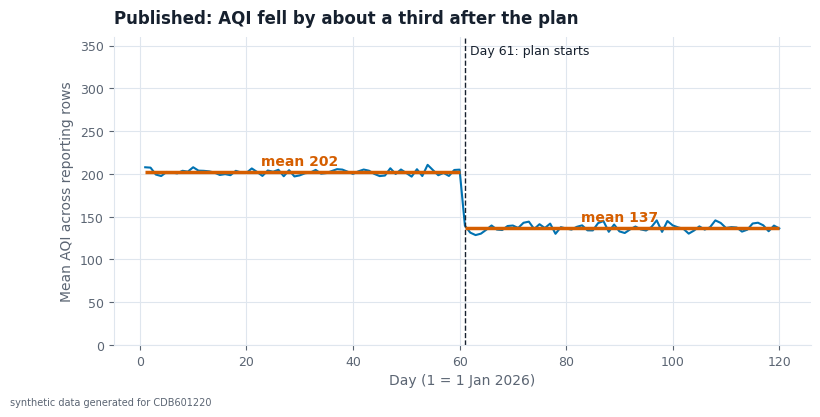

In [10]:
d3 = pd.read_csv(DATA / "case03_aqi_monitors.csv", parse_dates=["date"])
d3["day"] = (d3.date - d3.date.min()).dt.days + 1
daily = d3.groupby("day").aqi.mean()                 # pandas skips blanks silently!
before, after = daily.loc[:60].mean(), daily.loc[61:].mean()
print(f"before {before:.0f}   after {after:.0f}   change {after/before - 1:+.0%}")
assert round(before) == 202 and round(after) == 137

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily.index, daily.values, color=BLUE, lw=1.5)
ax.axvline(61, color=INK, ls="--", lw=1); ax.text(62, 340, "Day 61: plan starts", fontsize=9)
ax.hlines(before, 1, 60, color=VERM, lw=2.5); ax.hlines(after, 61, 120, color=VERM, lw=2.5)
ax.text(30, before + 8, f"mean {before:.0f}", color=VERM, ha="center", fontweight="bold")
ax.text(90, after + 8, f"mean {after:.0f}", color=VERM, ha="center", fontweight="bold")
ax.set_ylim(0, 360); ax.set_xlabel("Day (1 = 1 Jan 2026)"); ax.set_ylabel("Mean AQI across reporting rows")
ax.set_title("Published: AQI fell by about a third after the plan")
finish(fig, "A3_rebuild.png")

### 2 · Conclusion and decoy
**Conclusion the chart invites:** the plan cut Lahore's air pollution by **32%** (202 → 137).

**Decoy:** "The axis is truncated / exaggerates the fall." It isn't — the y-axis starts at **0** in the recipe and in my rebuild, so the *visual* drop equals the *numeric* drop.
The sample is not small either (2,640 station-days). The problem is *what is being averaged*.

### 3 · Mechanism — the set of stations being averaged changed (missing data that is not random)

In [11]:
rep = d3.groupby("day").aqi.count()
print("Stations reporting: days 1-60 =", rep.loc[:60].min(), "| days 61-120 =", rep.loc[61:].min(), "to", rep.loc[61:].max())
off = d3[d3.aqi.isna()].groupby(["zone", "station_id"]).day.min().reset_index()
print("\nStations that went blank, and from which day:"); print(off.groupby("zone").agg(stations=("station_id", "nunique"), first_blank_day=("day", "min")))
print("\nMean AQI by zone (days 1-60):"); print(d3[d3.day <= 60].groupby("zone").aqi.mean().round(0))

d3["period"] = np.where(d3.day <= 60, "before", "after")
same = d3[d3.station_id.isin(d3[d3.day > 60].dropna(subset=["aqi"]).station_id.unique())]
like = same.groupby("period").aqi.mean()
print(f"\nLike-for-like: the {same.station_id.nunique()} stations that report on all 120 days -> before {like['before']:.1f}, after {like['after']:.1f}  ({like['after']/like['before']-1:+.1%})")

Stations reporting: days 1-60 = 22 | days 61-120 = 13 to 13

Stations that went blank, and from which day:
            stations  first_blank_day
zone                                 
Arterial           3               61
Industrial         6               61

Mean AQI by zone (days 1-60):
zone
Arterial       245.0
Industrial     322.0
Peri-urban      79.0
Residential    122.0
Name: aqi, dtype: float64

Like-for-like: the 13 stations that report on all 120 days -> before 137.1, after 137.2  (+0.1%)


**Mechanism:** *survivorship in the denominator.* From day 61 **nine stations go blank — all 6 industrial stations and 3 of the 6 arterial ones** — and these are the dirtiest
(industrial mean ≈ 322, arterial ≈ 245, against ≈ 80–120 in peri-urban/residential). The "mean" after day 61 is therefore a mean over a **cleaner subset of the city**; `pandas.mean()` skips blanks without warning.
On the **13 stations that report on every one of the 120 days** the mean is **137.1 before and 137.2 after (+0.1%)** — the plan shows no effect at all in this data.

### 4 · Redesign — show the coverage, then compare like with like

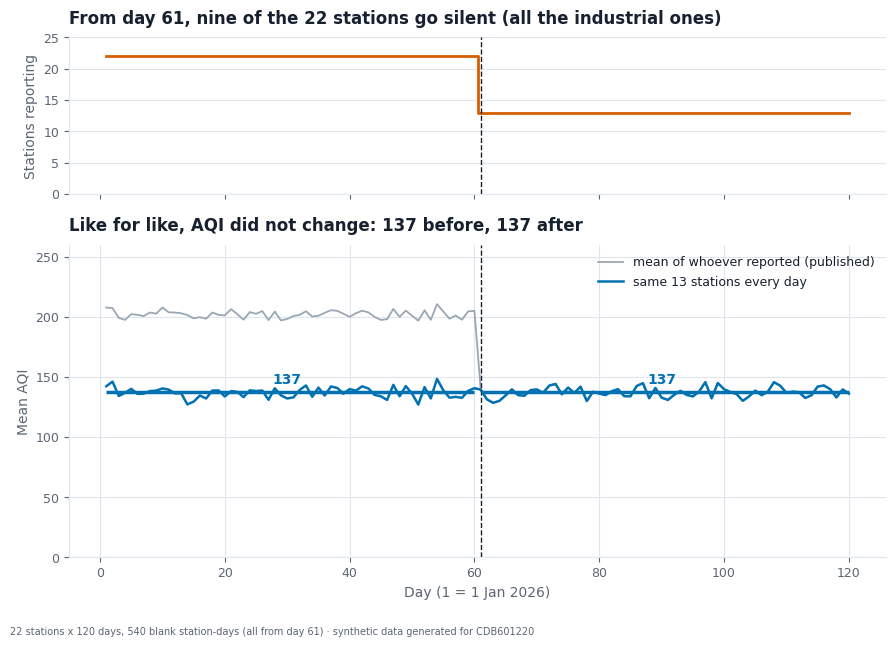

In [12]:
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
a.step(rep.index, rep.values, where="mid", color=VERM, lw=2); a.set_ylim(0, 25)
a.axvline(61, color=INK, ls="--", lw=1)
a.set_ylabel("Stations reporting"); a.set_title("From day 61, nine of the 22 stations go silent (all the industrial ones)")
a.grid(axis="x", visible=False)

same_daily = same.groupby("day").aqi.mean()
all_daily = daily
b.plot(all_daily.index, all_daily.values, color=GREY, lw=1.3, label="mean of whoever reported (published)")
b.plot(same_daily.index, same_daily.values, color=BLUE, lw=1.8, label="same 13 stations every day")
b.axvline(61, color=INK, ls="--", lw=1)
b.hlines(like["before"], 1, 60, color=BLUE, lw=2.5); b.hlines(like["after"], 61, 120, color=BLUE, lw=2.5)
b.text(30, like["before"] + 7, f"{like['before']:.0f}", color=BLUE, ha="center", fontweight="bold")
b.text(90, like["after"] + 7, f"{like['after']:.0f}", color=BLUE, ha="center", fontweight="bold")
b.set_ylim(0, 260); b.set_xlabel("Day (1 = 1 Jan 2026)"); b.set_ylabel("Mean AQI")
b.legend(loc="upper right"); b.set_title("Like for like, AQI did not change: 137 before, 137 after")
fig.tight_layout()
finish(fig, "A3_redesign.png", "22 stations x 120 days, 540 blank station-days (all from day 61) · synthetic data generated for CDB601220")

---
## Case 4 · "Four departments behave identically, so fund them equally"
### 1 · Rebuild (a table, not a chart)

In [13]:
d4 = pd.read_csv(DATA / "case04_quartet_depts.csv")
def stat_table(df, grp, x, y):
    rows = {}
    for k, s in df.groupby(grp, sort=False):
        rows[k] = {"n": len(s), f"mean {x}": s[x].mean(), f"mean {y}": s[y].mean(),
                   f"SD {x}": s[x].std(), f"SD {y}": s[y].std(),
                   "Pearson r": s[x].corr(s[y]), "slope": np.polyfit(s[x], s[y], 1)[0]}
    return pd.DataFrame(rows).round(3)
t4 = stat_table(d4, "department", "study_hours_per_week", "final_score_out_of_20")
t4

,Computer Science,Business Administration,Electrical Engineering,Architecture
n,11.000,11.000,11.000,11.000
mean study_hours_per_week,18.000,18.000,18.000,18.000
mean final_score_out_of_20,14.501,14.501,14.500,14.501
SD study_hours_per_week,6.633,6.633,6.633,6.633
SD final_score_out_of_20,2.032,2.032,2.030,2.031
Pearson r,0.816,0.816,0.816,0.817
slope,0.250,0.250,0.250,0.250


In [14]:
assert (t4.loc["mean study_hours_per_week"].round(2) == 18.00).all() and (t4.loc["mean final_score_out_of_20"].round(2) == 14.50).all()
assert (t4.loc["Pearson r"].round(2) == 0.82).all()
print("self-check passed: every department 18.00 / 14.50, r = 0.816 -> 0.82")

self-check passed: every department 18.00 / 14.50, r = 0.816 -> 0.82


### 2 · Conclusion and decoy
**Conclusion the table invites:** same mean hours, same mean score, same spread, same r = 0.82, same slope (0.25 marks per weekly hour) → the four departments are the same → fund them equally.

**Decoy:** "n = 11 is too small to say anything." It is the same n in every department — if n were the problem the *table* could not look this identical, and the plot below shows the structure plainly at n = 11.

### 3 · Mechanism — summary statistics do not constrain shape
Mean, SD, r and slope are five numbers that compress 11 points; infinitely many different shapes share them (this is Anscombe's 1973 quartet). I check what the statistics hide by measuring the *fit of a straight line*:

In [15]:
for k, s in d4.groupby("department", sort=False):
    x, y = s.study_hours_per_week, s.final_score_out_of_20
    b1, b0 = np.polyfit(x, y, 1); res = y - (b1 * x + b0)
    q = np.polyfit(x, y, 2); r2q = 1 - ((y - np.polyval(q, x))**2).sum() / ((y - y.mean())**2).sum()
    infl = stats.pearsonr(x.drop(res.abs().idxmax()), y.drop(res.abs().idxmax())).statistic
    warnings.simplefilter("ignore")
    print(f"{k:24s} R2 linear {1 - (res**2).sum()/((y-y.mean())**2).sum():.2f} | R2 quadratic {r2q:.2f} | "
          f"largest residual {res.abs().max():.2f} | r without that point {infl:.2f} | distinct hours values {x.nunique()}")

Computer Science         R2 linear 0.67 | R2 quadratic 0.69 | largest residual 1.92 | r without that point 0.89 | distinct hours values 11
Business Administration  R2 linear 0.67 | R2 quadratic 1.00 | largest residual 1.90 | r without that point 0.89 | distinct hours values 11
Electrical Engineering   R2 linear 0.67 | R2 quadratic 0.68 | largest residual 3.24 | r without that point 1.00 | distinct hours values 11
Architecture             R2 linear 0.67 | R2 quadratic 0.67 | largest residual 1.84 | r without that point 0.86 | distinct hours values 2


**Mechanism:** the identical numbers hide four different data-generating stories — one department is a genuine straight-line relationship, one is a **curve** (Business Administration: R² of a straight line 0.67, of a quadratic **1.00**),
one is a straight line **pulled off by a single outlier** (Electrical Engineering: largest residual 3.24, and r would be **1.00** without that point) and one has **only two distinct values of study hours** (Architecture: 10 students at the same hours), so the entire slope hangs on one point (a leverage point). Computer Science is the plain, noisy straight line.
Funding "equally" because the table matches would treat four different situations as one.

### 4 · Redesign — plot all four on shared axes

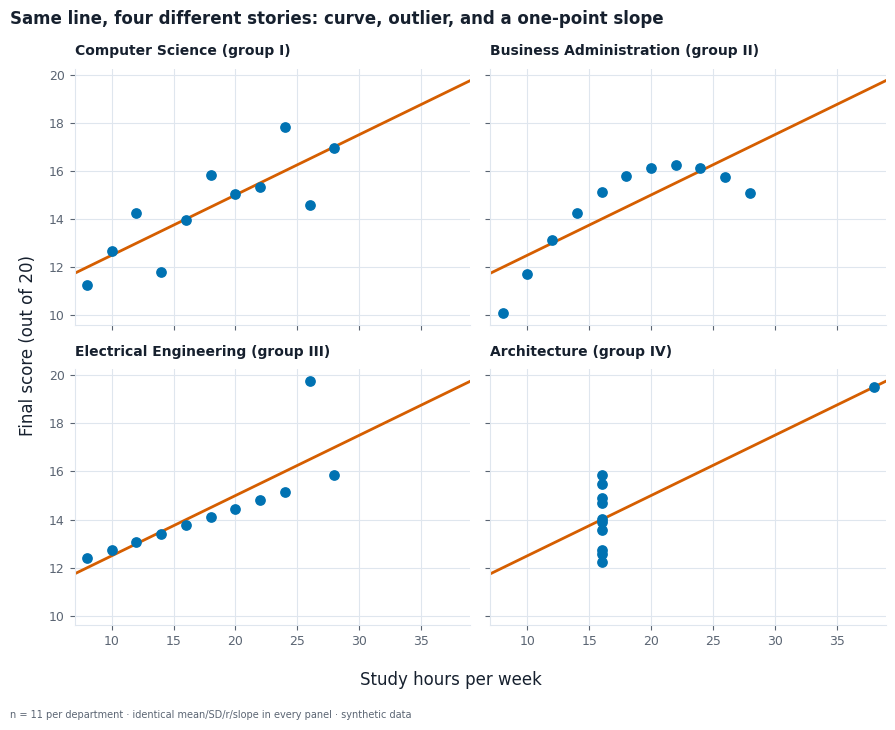

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
xs = np.array([d4.study_hours_per_week.min() - 1, d4.study_hours_per_week.max() + 1])
for ax, (k, s) in zip(axes.flat, d4.groupby("department", sort=False)):
    ax.scatter(s.study_hours_per_week, s.final_score_out_of_20, color=BLUE, s=45, zorder=3)
    b1, b0 = np.polyfit(s.study_hours_per_week, s.final_score_out_of_20, 1)
    ax.plot(xs, b1 * xs + b0, color=VERM, lw=2)                 # the SAME line in all four panels
    ax.set_title(f"{k} (group {s.cohort_group.iloc[0]})", fontsize=10)
    ax.set_xlim(xs[0], xs[1])
fig.supxlabel("Study hours per week"); fig.supylabel("Final score (out of 20)")
fig.suptitle("Same line, four different stories: curve, outlier, and a one-point slope", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
finish(fig, "A4_redesign.png", "n = 11 per department · identical mean/SD/r/slope in every panel · synthetic data")

---
## Case 5 · "Five cohorts, one set of statistics"
### 1 · Rebuild (a table)

In [17]:
d5 = pd.read_csv(DATA / "case05_same_stats_shapes.csv")
t5 = stat_table(d5, "shape_name", "hours_on_platform", "assessment_score")
t5

,straight line,ring,star,two clusters,the letter X
n,180.000,180.000,180.000,180.000,180.000
mean hours_on_platform,48.000,48.000,48.000,48.000,48.000
mean assessment_score,63.000,63.000,63.000,63.000,63.000
SD hours_on_platform,12.033,12.033,12.033,12.033,12.033
SD assessment_score,15.042,15.042,15.042,15.042,15.042
Pearson r,0.420,0.420,0.420,0.420,0.420
slope,0.525,0.525,0.525,0.525,0.525


In [18]:
for k in t5.columns:
    s = d5[d5.shape_name == k]
    assert round(s.hours_on_platform.mean(), 2) == 48.00 and round(s.assessment_score.mean(), 2) == 63.00
    assert round(s.hours_on_platform.std(ddof=0), 2) == 12.00 and round(s.assessment_score.std(ddof=0), 2) == 15.00
    assert round(s.hours_on_platform.corr(s.assessment_score), 3) == 0.420
print("self-check passed: 48.00 / 63.00, SD 12.00 / 15.00 (population SD), r = 0.420 for all five")

self-check passed: 48.00 / 63.00, SD 12.00 / 15.00 (population SD), r = 0.420 for all five


### 2 · Conclusion and decoy
**Conclusion the table invites:** five cohorts with identical statistics are the same population; one model (r = 0.42, slope 0.525) describes them all.

**Decoy:** "n is too small." Here n = **180** per cohort — large — and the statistics are *still* identical to two decimals. More data does not rescue a summary table.

### 3 · Mechanism — the statistics are forced, not discovered
`vizlib.match_stats()` shows how: standardise x, residualise y, rebuild y = r·zx + √(1−r²)·residual and rescale. The mean, SD and r are exact **by construction**, whatever the starting shape is
(the Datasaurus Dozen method, Matejka & Fitzmaurice 2017). Mean, SD and r only describe the first two moments and one linear association, so they cannot distinguish a line, a ring, a star, two clusters and a letter X.
Even the residual spread around the regression line is identical (13.7) — yet a simple *spatial* check (how many cells of a 6×6 grid are occupied, how many distinct x-values exist) separates the shapes immediately:

In [19]:
for k, s in d5.groupby("shape_name"):
    X = np.c_[s.hours_on_platform, s.assessment_score]
    ev = np.sort(np.linalg.eigvalsh(np.cov(X.T)))
    # spread unexplained by the straight line:
    b1, b0 = np.polyfit(s.hours_on_platform, s.assessment_score, 1)
    resid_sd = (s.assessment_score - (b1 * s.hours_on_platform + b0)).std()
    hist = np.histogram2d(s.hours_on_platform, s.assessment_score, bins=6)[0]
    print(f"{k:14s} distinct x values {s.hours_on_platform.nunique():3d} | occupied 6x6 cells {(hist > 0).sum():2d}/36 | residual SD {resid_sd:.1f}")

ring           distinct x values 180 | occupied 6x6 cells 21/36 | residual SD 13.7
star           distinct x values  90 | occupied 6x6 cells 27/36 | residual SD 13.7
straight line  distinct x values 180 | occupied 6x6 cells 31/36 | residual SD 13.7
the letter X   distinct x values  90 | occupied 6x6 cells 17/36 | residual SD 13.7
two clusters   distinct x values 180 | occupied 6x6 cells 22/36 | residual SD 13.7


### 4 · Redesign — small multiples, one panel per cohort

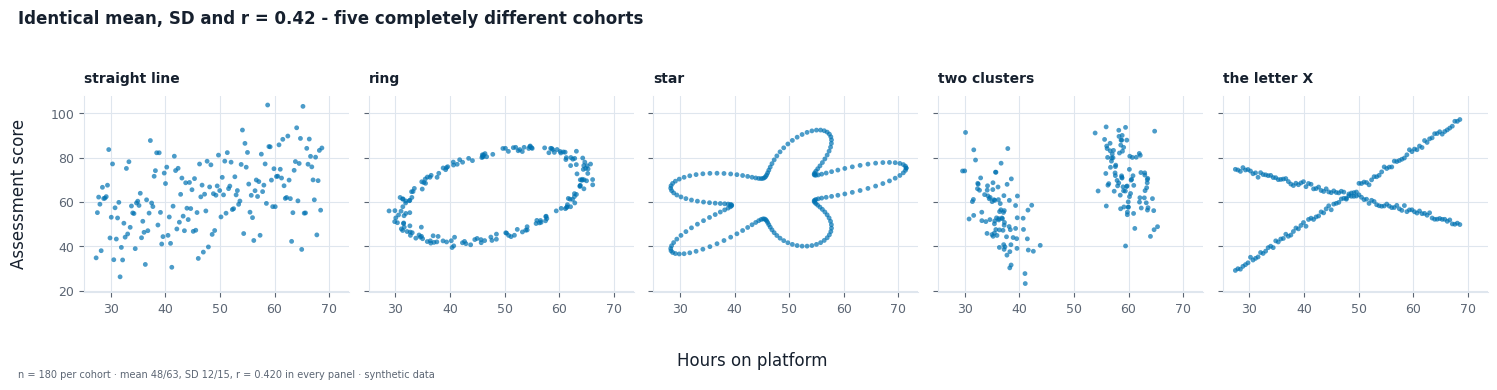

In [20]:
order = ["straight line", "ring", "star", "two clusters", "the letter X"]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharex=True, sharey=True)
for ax, k in zip(axes, order):
    s = d5[d5.shape_name == k]
    ax.scatter(s.hours_on_platform, s.assessment_score, color=BLUE, s=12, alpha=0.7, edgecolor="none")
    ax.set_title(k, fontsize=10)
fig.supxlabel("Hours on platform", y=-0.02); fig.supylabel("Assessment score", x=0.005)
fig.suptitle("Identical mean, SD and r = 0.42 - five completely different cohorts", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.04)
fig.tight_layout()
finish(fig, "A5_redesign.png", "n = 180 per cohort · mean 48/63, SD 12/15, r = 0.420 in every panel · synthetic data")

---
## Case 6 · "Creatinine tracks HbA1c — a finding"
### 1 · Rebuild (exactly as the analyst drew it)

matrix shape: (20, 20) | creatinine<->hba1c = 0.77 | systolic<->map_mmhg = 0.96


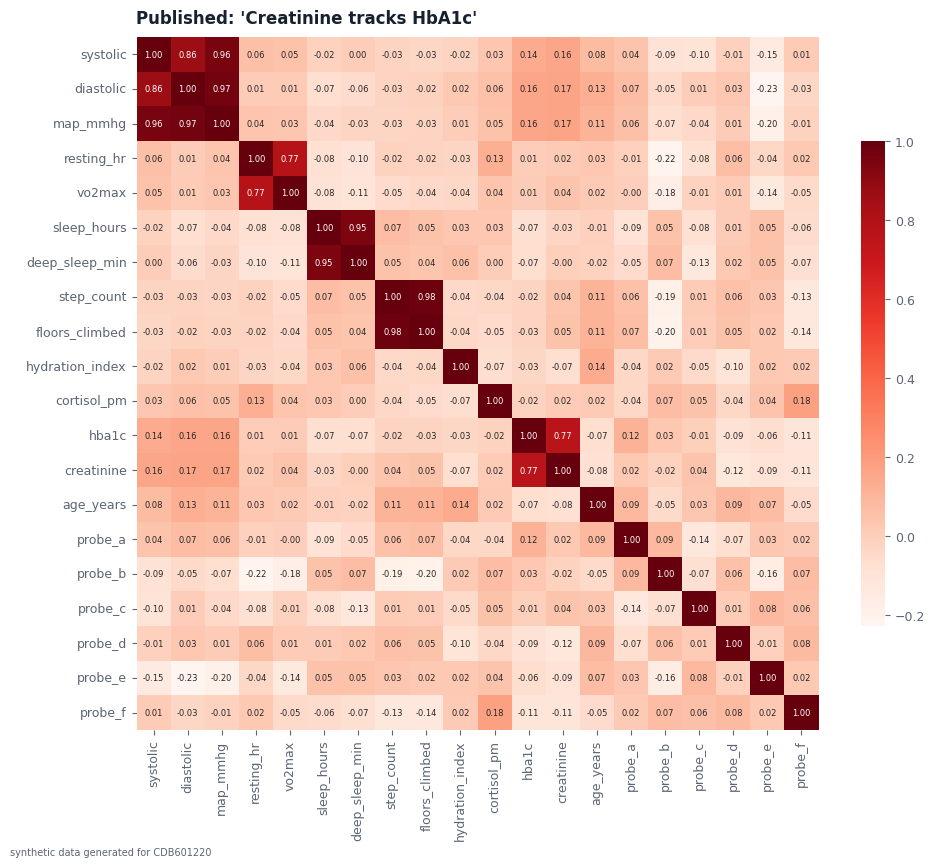

In [21]:
d6 = pd.read_csv(DATA / "case06_sensor_matrix.csv")
num = d6.drop(columns=["age_band", "study_site", "hr_device_model"])
R = num.corr()
print("matrix shape:", R.shape, "| creatinine<->hba1c =", round(R.loc["creatinine", "hba1c"], 2), "| systolic<->map_mmhg =", round(R.loc["systolic", "map_mmhg"], 2))
assert R.shape == (20, 20) and round(R.loc["creatinine", "hba1c"], 2) == 0.77 and round(R.loc["systolic", "map_mmhg"], 2) == 0.96

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(R, cmap="Reds", annot=True, fmt=".2f", annot_kws={"size": 6}, ax=ax, cbar_kws={"shrink": 0.7})   # no vmin/vmax, both triangles
ax.set_title("Published: 'Creatinine tracks HbA1c'"); ax.grid(False)
finish(fig, "A6_rebuild.png")

### 2 · Conclusion and decoy
**Conclusion the chart invites:** creatinine and HbA1c rise together (r = 0.77) — a clinical finding worth a paper.

**Decoy:** "Both rise with age, so age confounds it." Test it by partialling age out:

In [22]:
def partial_r(df, x, y, z):
    zz = np.c_[np.ones(len(df)), df[z].values]
    rx = df[x] - zz @ np.linalg.lstsq(zz, df[x], rcond=None)[0]
    ry = df[y] - zz @ np.linalg.lstsq(zz, df[y], rcond=None)[0]
    return np.corrcoef(rx, ry)[0, 1]
print("r(creatinine, hba1c)               =", round(R.loc["creatinine", "hba1c"], 3))
print("partial r controlling for age      =", round(partial_r(num, "creatinine", "hba1c", ["age_years"]), 3))
print("r(age, creatinine) =", round(R.loc["age_years", "creatinine"], 2), "| r(age, hba1c) =", round(R.loc["age_years", "hba1c"], 2))

r(creatinine, hba1c)               = 0.765
partial r controlling for age      = 0.764
r(age, creatinine) = -0.08 | r(age, hba1c) = -0.07


**Why the decoy fails:** age is correlated with neither variable (|r| ≈ 0.1 or less), and the partial correlation barely moves. Age is not what is producing 0.77.

### 3 · Mechanism — one participant, plus a drawing that hides the sign

In [23]:
top = num.sort_values("creatinine", ascending=False).head(4)[["hba1c", "creatinine"]]
print(top)
print("\nPearson r, all 180 participants   :", round(num.hba1c.corr(num.creatinine), 3))
without = num.drop(index=top.index[0])
print("Pearson r, without that ONE row   :", round(without.hba1c.corr(without.creatinine), 3))
sp = stats.spearmanr(num.hba1c, num.creatinine)
print(f"Spearman (rank-based), all rows   : {sp.statistic:.3f} (p = {sp.pvalue:.2f})")

iu = np.triu_indices(20, 1); rr = R.values[iu]; n = len(num)
p = 2 * stats.t.sf(np.abs(rr * np.sqrt((n - 2) / (1 - rr**2))), n - 2)
print(f"\n{len(rr)} pairs in the matrix; {(p < 0.05).sum()} with p < .05 (about {0.05*len(rr):.1f} expected by chance alone); lowest r in the whole matrix = {R.values.min():.2f}")
pairs = sorted(((R.index[i], R.columns[j], R.values[i, j]) for i, j in zip(*iu)), key=lambda t: -abs(t[2]))[:8]
for a_, b_, v_ in pairs: print(f"   {a_:15s} {b_:15s} {v_:+.2f}")

     hba1c  creatinine
0    15.80      1050.0
178   4.73       111.4
129   7.30       107.6
55    4.43       105.6

Pearson r, all 180 participants   : 0.765
Pearson r, without that ONE row   : -0.004
Spearman (rank-based), all rows   : 0.032 (p = 0.67)

190 pairs in the matrix; 20 with p < .05 (about 9.5 expected by chance alone); lowest r in the whole matrix = -0.23
   step_count      floors_climbed  +0.98
   diastolic       map_mmhg        +0.97
   systolic        map_mmhg        +0.96
   sleep_hours     deep_sleep_min  +0.95
   systolic        diastolic       +0.86
   resting_hr      vo2max          +0.77
   hba1c           creatinine      +0.77
   diastolic       probe_e         -0.23


**Two separate faults — and only one of them is fixed by redrawing:**

1. **How it is drawn.** `cmap="Reds"` with no `vmin/vmax` maps the *data range* (−0.23 … 1.00) onto white→red, so **the sign is not visible at all** — a negative correlation is the same pale as a zero one; the colour scale is not centred on 0 and not pinned to ±1;
   both triangles and the diagonal repeat/pad the same information, and 20 × 20 numbers in cells is a table, not a chart. *Redrawing (diverging map pinned to −1…+1, upper triangle masked) fixes this.*
2. **What it says.** The 0.77 comes from **a single participant** (HbA1c 15.8, creatinine 1,050 µmol/L — an extreme row). Remove that one row and r = **−0.004**; the rank-based Spearman on all 180 is **0.03**.
   No colour map can fix that: *a clean heatmap would still print 0.77.* The other big cells are structural, not findings — `map_mmhg` is computed from systolic/diastolic, steps↔floors, sleep↔deep-sleep, and so on. And with 190 pairs, about 9–10 "significant" ones are expected by chance.

### 4 · Redesign — fix the drawing, show it does not fix the claim, then show the real picture

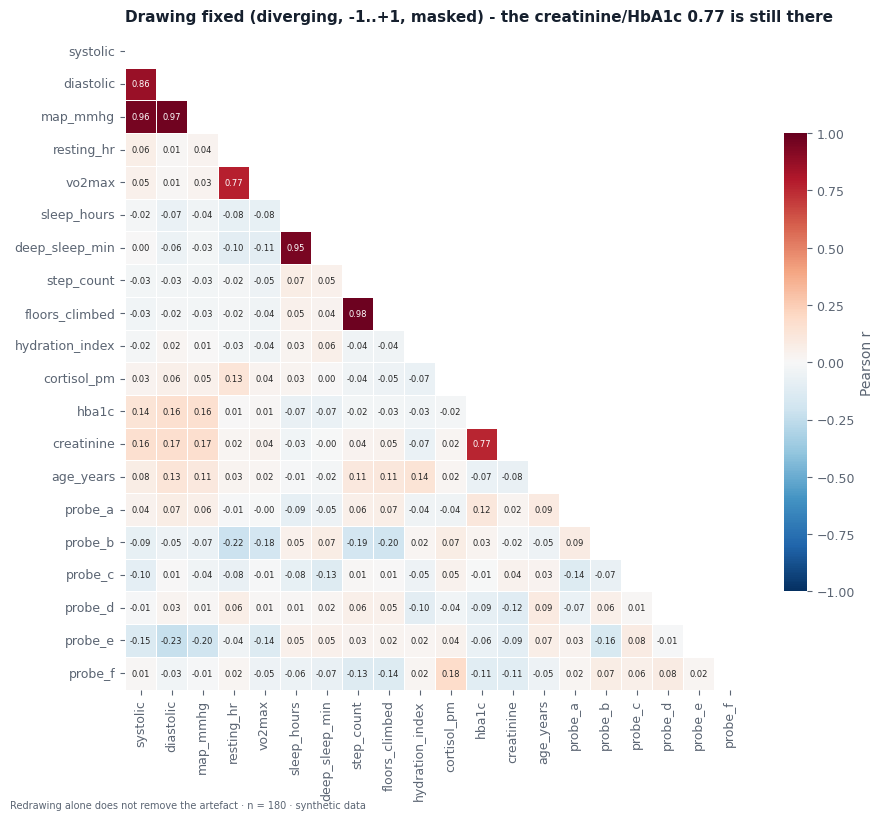

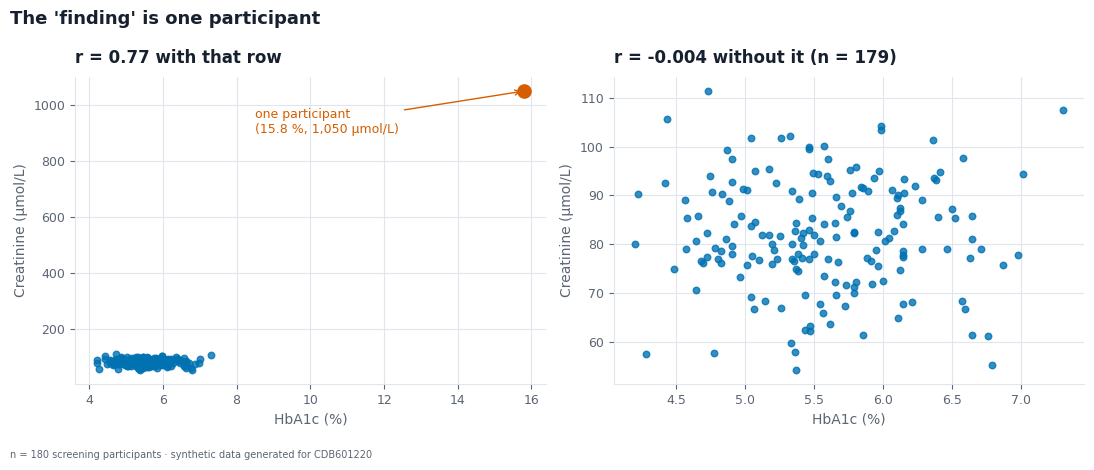

In [24]:
fig, ax = plt.subplots(figsize=(10, 8.5))
mask = np.triu(np.ones_like(R, dtype=bool))
sns.heatmap(R, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 6},
            linewidths=0.4, linecolor="white", ax=ax, cbar_kws={"shrink": 0.7, "label": "Pearson r"})
ax.set_title("Drawing fixed (diverging, -1..+1, masked) - the creatinine/HbA1c 0.77 is still there", loc="left", fontsize=11)
ax.grid(False)
finish(fig, "A6_redesign_a_drawing_fixed.png", "Redrawing alone does not remove the artefact · n = 180 · synthetic data")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.4))
a.scatter(num.hba1c, num.creatinine, color=BLUE, s=22, alpha=0.8)
a.scatter(*top.iloc[0][["hba1c", "creatinine"]], color=VERM, s=90, zorder=3)
a.annotate("one participant\n(15.8 %, 1,050 µmol/L)", xy=(15.8, 1050), xytext=(8.5, 900), arrowprops=dict(arrowstyle="->", color=VERM), color=VERM, fontsize=9)
a.set_xlabel("HbA1c (%)"); a.set_ylabel("Creatinine (µmol/L)"); a.set_title("r = 0.77 with that row")
b.scatter(without.hba1c, without.creatinine, color=BLUE, s=22, alpha=0.8)
rw = without.hba1c.corr(without.creatinine)
b.set_xlabel("HbA1c (%)"); b.set_ylabel("Creatinine (µmol/L)"); b.set_title(f"r = {rw:.3f} without it (n = 179)")
fig.suptitle("The 'finding' is one participant", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
finish(fig, "A6_redesign_b_the_real_story.png", "n = 180 screening participants · synthetic data generated for CDB601220")

---
## Case 7 · "ShaheenGo ran at a loss until May"
### 1 · Rebuild

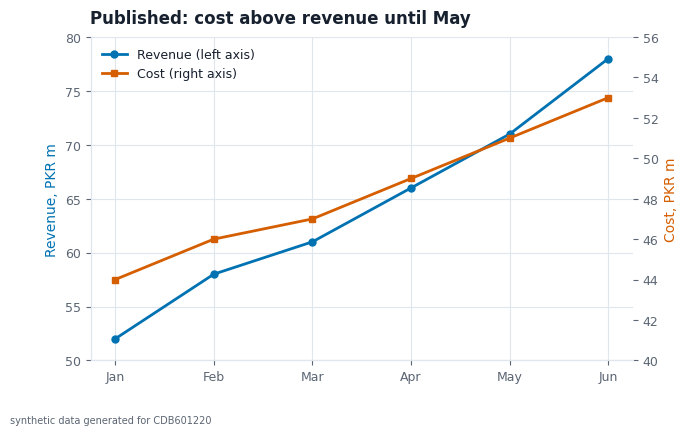

cost line above revenue line on screen: ['Jan', 'Feb', 'Mar', 'Apr']


In [25]:
d7 = pd.read_csv(DATA / "case07_dual_axis_series.csv")
fig, ax = plt.subplots(figsize=(7, 4.2))
l1, = ax.plot(d7.month, d7.revenue_pkr_m, color=BLUE, marker="o", label="Revenue (left axis)")
ax.set_ylim(50, 80); ax.set_ylabel("Revenue, PKR m", color=BLUE)
ax2 = ax.twinx()                                                   # exactly what the recipe says
l2, = ax2.plot(d7.month, d7.cost_pkr_m, color=VERM, marker="s", label="Cost (right axis)")
ax2.set_ylim(40, 56); ax2.set_ylabel("Cost, PKR m", color=VERM); ax2.grid(False)
ax.set_title("Published: cost above revenue until May")
ax.legend(handles=[l1, l2], loc="upper left")
finish(fig, "A7_rebuild.png")

# self-check: where does the cost line sit ABOVE the revenue line, in screen position?
pos_rev = (d7.revenue_pkr_m - 50) / (80 - 50)
pos_cost = (d7.cost_pkr_m - 40) / (56 - 40)
print("cost line above revenue line on screen:", list(d7.month[pos_cost > pos_rev]))
assert list(d7.month[pos_cost > pos_rev]) == ["Jan", "Feb", "Mar", "Apr"]

### 2 · Conclusion and decoy
**Conclusion the chart invites:** the lines cross between April and May, so the company lost money until May.

**Decoy:** "The y-axis is truncated." It is — *both* are, and the recipe says so — but truncation by itself is not what manufactures the crossing (a truncated *shared* axis would still draw revenue above cost). Check what the numbers say:

In [26]:
d7["profit_m"] = d7.revenue_pkr_m - d7.cost_pkr_m
d7["margin_%"] = (d7.profit_m / d7.revenue_pkr_m * 100).round(1)
print(d7)
print("\nMonths with cost > revenue (actual numbers):", int((d7.cost_pkr_m > d7.revenue_pkr_m).sum()))

  month  revenue_pkr_m  cost_pkr_m  profit_m  margin_%
0   Jan             52          44         8      15.4
1   Feb             58          46        12      20.7
2   Mar             61          47        14      23.0
3   Apr             66          49        17      25.8
4   May             71          51        20      28.2
5   Jun             78          53        25      32.1

Months with cost > revenue (actual numbers): 0


**Why the decoy is not the point:** in the numbers cost is *never* above revenue — revenue exceeds cost by PKR 8 m already in January.

### 3 · Mechanism — two independent scales, so "crossing" has no meaning
Both series are in PKR millions, but the left axis spans **30** units (50–80) and the right spans **16** (40–56). Where two lines cross is decided by *which two ranges the author typed*, not by the data.
I show it by moving only the right-axis limits (screen position = (value − lower)/(upper − lower)):

In [27]:
def months_cost_above(left=(50, 80), right=(40, 56)):
    pr = (d7.revenue_pkr_m - left[0]) / (left[1] - left[0]); pc = (d7.cost_pkr_m - right[0]) / (right[1] - right[0])
    return list(d7.month[pc > pr])
for rng in [(40, 56), (40, 80), (30, 60), (44, 53), (20, 60)]:
    print(f"right axis {rng}:  cost drawn above revenue in {months_cost_above(right=rng) or 'no month'}")

right axis (40, 56):  cost drawn above revenue in ['Jan', 'Feb', 'Mar', 'Apr']
right axis (40, 80):  cost drawn above revenue in ['Jan']
right axis (30, 60):  cost drawn above revenue in ['Jan', 'Feb', 'Mar', 'Apr']
right axis (44, 53):  cost drawn above revenue in ['Apr', 'May', 'Jun']
right axis (20, 60):  cost drawn above revenue in ['Jan', 'Feb', 'Mar', 'Apr', 'May']


Change the right axis from 40–56 to 40–80 and the "loss until May" vanishes; pick 40–80 and the cost line is "above" revenue only in January; pick 44–53 and the "loss" *moves* to April–June; pick 20–60 and it lasts five months. The "event" (a cross-over in May) is a property of the axis choice. In the data, **margin grew from 15% (Jan) to 32% (Jun)**; there was never a loss.

### 4 · Redesign — one shared axis, from zero, with the gap as its own panel

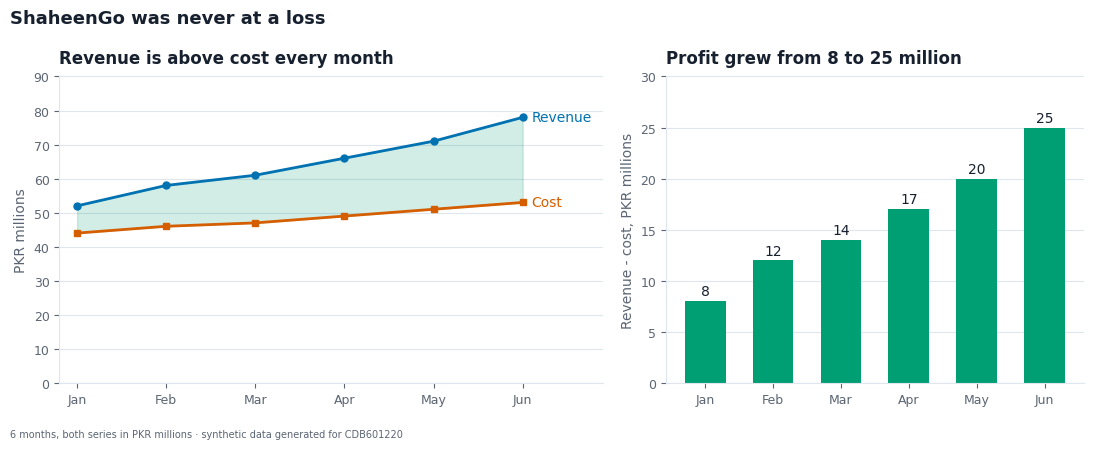

In [28]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
a.plot(d7.month, d7.revenue_pkr_m, color=BLUE, marker="o"); a.plot(d7.month, d7.cost_pkr_m, color=VERM, marker="s")
a.fill_between(d7.month, d7.cost_pkr_m, d7.revenue_pkr_m, color=GREEN, alpha=0.18)
a.text(5.1, d7.revenue_pkr_m.iloc[-1], "Revenue", color=BLUE, va="center"); a.text(5.1, d7.cost_pkr_m.iloc[-1], "Cost", color=VERM, va="center")
a.set_ylim(0, 90); a.set_xlim(-0.2, 5.9); a.set_ylabel("PKR millions"); a.grid(axis="x", visible=False)
a.set_title("Revenue is above cost every month")
bb = b.bar(d7.month, d7.profit_m, color=GREEN, width=0.6); b.bar_label(bb, padding=2, fmt="%d")
b.set_ylim(0, 30); b.set_ylabel("Revenue - cost, PKR millions"); b.grid(axis="x", visible=False)
b.set_title("Profit grew from 8 to 25 million")
fig.suptitle("ShaheenGo was never at a loss", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
finish(fig, "A7_redesign.png", "6 months, both series in PKR millions · synthetic data generated for CDB601220")

---
## Case 8 · "Three bin widths, three different distributions"
### 1 · Rebuild

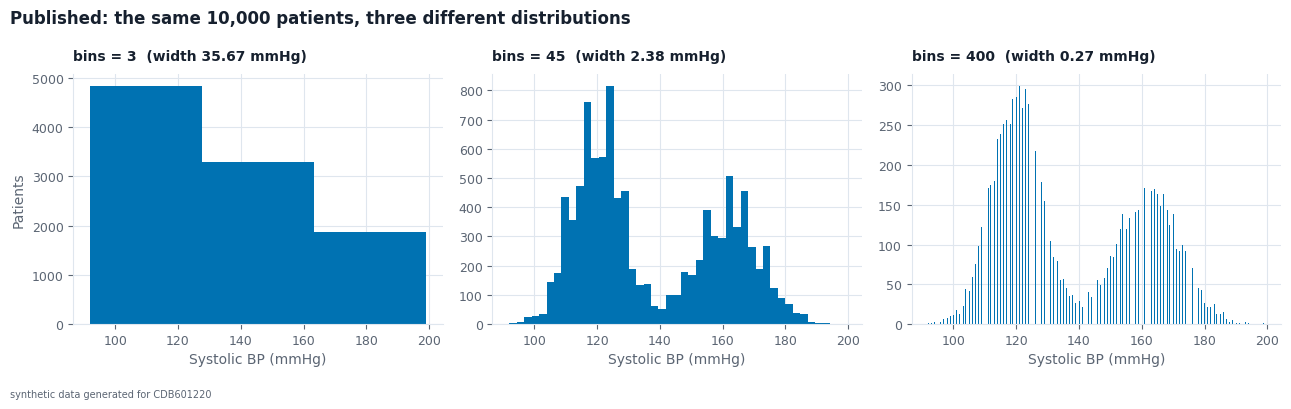

In [29]:
v = pd.read_csv(DATA / "vitals_10k.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, b in zip(axes, [3, 45, 400]):
    counts, edges, _ = ax.hist(v.systolic, bins=b, color=BLUE)
    assert counts.sum() == 10000                                       # self-check: n = 10,000 in every panel
    ax.set_title(f"bins = {b}  (width {edges[1]-edges[0]:.2f} mmHg)", fontsize=10)
    ax.set_xlabel("Systolic BP (mmHg)")
axes[0].set_ylabel("Patients")
fig.suptitle("Published: the same 10,000 patients, three different distributions", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
finish(fig, "A8_rebuild.png")

### 2 · Conclusion and decoy
**Conclusion the chart invites:** the data has no stable shape — one hump, two humps or a jagged comb depending on whom you ask; therefore "the distribution" is whatever the analyst wants.

**Decoy:** "n is too small, so the shape is unstable." n is **10,000 in all three panels**. This is not sampling noise; the data are identical in all three.

### 3 · Mechanism — bin width is a parameter that *decides* the picture

In [30]:
print("distinct systolic values:", v.systolic.nunique(), "(integers", v.systolic.min(), "to", v.systolic.max(), ")")
for b in [3, 45, 400]:
    counts, edges = np.histogram(v.systolic, bins=b)
    print(f"bins={b:3d}: width {edges[1]-edges[0]:5.2f} mmHg | empty bins {(counts == 0).sum():3d}/{b} | tallest bin {counts.max()}")

distinct systolic values: 104 (integers 92 to 199 )
bins=  3: width 35.67 mmHg | empty bins   0/3 | tallest bin 4829
bins= 45: width  2.38 mmHg | empty bins   0/45 | tallest bin 814
bins=400: width  0.27 mmHg | empty bins 296/400 | tallest bin 299


**Mechanism:** the width of a bin is a smoothing parameter. With **3 bins** (width ≈ 35.7 mmHg) both humps are averaged into one lump and the bimodality is **erased**.
With **400 bins** (width 0.27 mmHg) the bins are narrower than the measurement itself: systolic pressure is recorded in **whole mmHg**, so most bins can never contain a value —
**296 of the 400 bins (74%) are empty** (see output) and the picture is a comb of integer spikes, an artefact of bins narrower than the instrument's resolution.
The honest bin width is somewhere between the resolution (1 mmHg) and the width of the features: **45 bins (≈ 2.4 mmHg) already shows the real structure: two populations.**

### 4 · Redesign — one histogram, bin width declared, modes marked

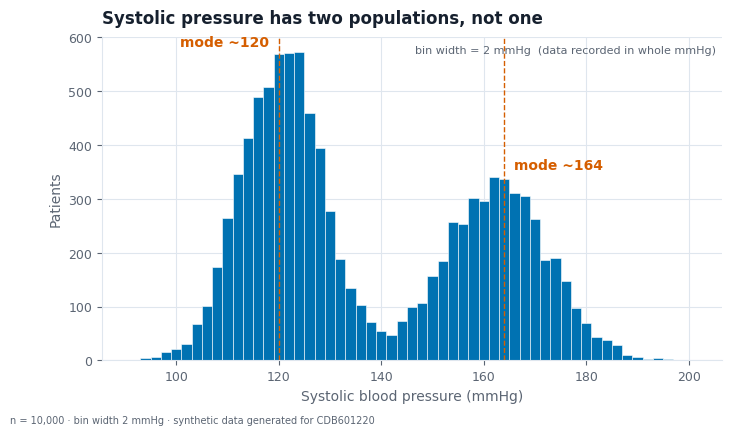

modes: 120.0 164.0 | share of patients above 140 mmHg: 41.6 %


In [31]:
bw = 2
edges = np.arange(v.systolic.min() - 1, v.systolic.max() + bw + 1, bw)
fig, ax = plt.subplots(figsize=(8, 4.2))
counts, e, _ = ax.hist(v.systolic, bins=edges, color=BLUE, edgecolor="white", linewidth=0.4)
mid = (e[:-1] + e[1:]) / 2
sm = np.convolve(counts, np.ones(5) / 5, mode="same")
lo = mid < 140; hi = ~lo
m1 = mid[lo][sm[lo].argmax()]; m2 = mid[hi][sm[hi].argmax()]
for m_ in (m1, m2): ax.axvline(m_, color=VERM, ls="--", lw=1)
ax.text(m1 - 2, counts.max() * 1.02, f"mode ~{m1:.0f}", color=VERM, ha="right", fontweight="bold")
ax.text(m2 + 2, counts.max() * 0.62, f"mode ~{m2:.0f}", color=VERM, ha="left", fontweight="bold")
ax.set_xlabel("Systolic blood pressure (mmHg)"); ax.set_ylabel("Patients")
ax.set_title("Systolic pressure has two populations, not one", loc="left")
ax.text(0.99, 0.95, f"bin width = {bw} mmHg  (data recorded in whole mmHg)", transform=ax.transAxes, ha="right", fontsize=8, color=PALETTE["ink_soft"])
finish(fig, "A8_redesign.png", "n = 10,000 · bin width 2 mmHg · synthetic data generated for CDB601220")
print("modes:", m1, m2, "| share of patients above 140 mmHg:", round((v.systolic > 140).mean() * 100, 1), "%")

---
## Case 9 · "4.4% of the density sits above 100% saturation"
### 1 · Rebuild

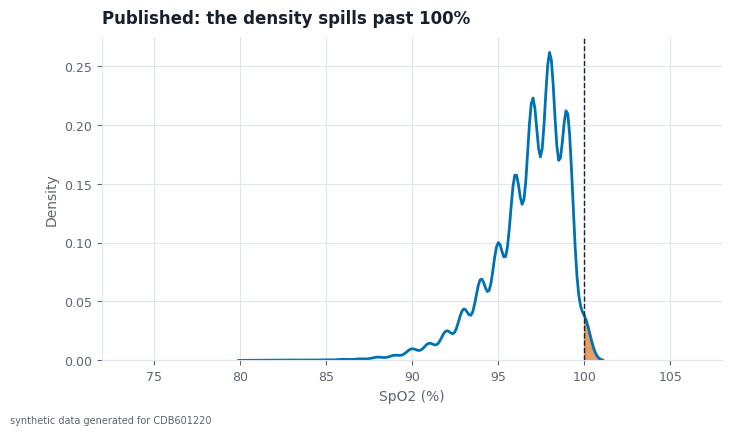

max SpO2 in the data: 100
density mass drawn above 100 with the default bandwidth: 1.55%


In [32]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.kdeplot(v.spo2, ax=ax, color=BLUE, lw=2)                       # DEFAULT bandwidth
ax.set_xlim(72, 108)                                               # extend to 108 so the whole curve is visible
ax.axvline(100, color=INK, ls="--", lw=1)
xk, yk = ax.lines[0].get_data(); m = xk > 100
ax.fill_between(xk[m], 0, yk[m], color=VERM, alpha=0.6)
mass = np.trapezoid(yk[m], xk[m]) / np.trapezoid(yk, xk)
ax.set_xlabel("SpO2 (%)"); ax.set_ylabel("Density"); ax.set_title("Published: the density spills past 100%")
finish(fig, "A9_rebuild.png")
print("max SpO2 in the data:", v.spo2.max())                       # self-check: 100
print(f"density mass drawn above 100 with the default bandwidth: {mass:.2%}")
assert v.spo2.max() == 100

### 2 · Conclusion and decoy
**Conclusion the chart invites:** some patients have impossible oxygen saturation above 100% — the data contain entry errors.

**Decoy:** "There are bad rows in the data." There are none: the **maximum value in the file is exactly 100**, and no row exceeds it. The impossible region exists only on the *curve*.
(The headline "4.4%" is not reproduced by the default bandwidth in my run — seaborn's default (Scott, ≈ 0.35 points) gives **≈ 1.6%**; 4.4% needs a bandwidth of about 0.9 points. The figure depends on the bandwidth, which is exactly the point, see below. Either way it is non-zero, and it is not data.)

In [33]:
print("rows with spo2 > 100:", (v.spo2 > 100).sum(), "| rows at exactly 100:", (v.spo2 == 100).sum(), f"({(v.spo2 == 100).mean():.1%})")
sd = v.spo2.std(ddof=1)
xs = np.linspace(60, 130, 14001); dx = xs[1] - xs[0]
print("\nbandwidth (SpO2 %-points)  ->  share of density above 100")
for bwid in [0.35, 0.5, 0.7, 0.9, 1.0, 1.5]:
    k = stats.gaussian_kde(v.spo2, bw_method=bwid / sd)
    print(f"        {bwid:4.2f}               ->  {k(xs)[xs > 100].sum() * dx:.1%}")
k0 = stats.gaussian_kde(v.spo2)
print(f"\nscott default = {k0.factor * sd:.2f} points  ->  {k0(xs)[xs > 100].sum() * dx:.1%}")

rows with spo2 > 100: 0 | rows at exactly 100: 304 (3.0%)

bandwidth (SpO2 %-points)  ->  share of density above 100


        0.35               ->  1.5%


        0.50               ->  1.9%


        0.70               ->  3.0%


        0.90               ->  4.3%


        1.00               ->  5.0%


        1.50               ->  8.7%



scott default = 0.35 points  ->  1.6%


### 3 · Mechanism — a kernel smoother does not know about physical ceilings
A KDE puts a small bell curve on **every** reading and adds them up. The bell has support on the whole real line, so readings *at* the boundary leak half their mass past it.
Here **3.0% of patients sit at exactly 100** (a hard ceiling — and the data are whole numbers), so there is a pile-up right at the wall and about half of it spills over: ≈ 1.5% of the mass at the default bandwidth, **about 5% with a bandwidth of 1 point**. The number is a function of the bandwidth parameter (printed above), not a property of any patient.

### 4 · Redesign — draw what was measured: counts per whole-number value, with the ceiling marked

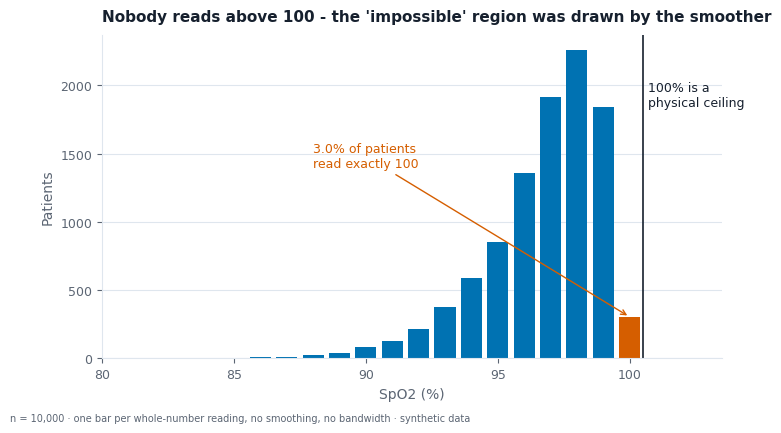

In [34]:
vc = v.spo2.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
cols = [VERM if i == 100 else BLUE for i in vc.index]
bars = ax.bar(vc.index, vc.values, color=cols, width=0.8)
ax.axvline(100.5, color=INK, lw=1.2); ax.text(100.7, vc.max() * 0.9, "100% is a\nphysical ceiling", fontsize=9, va="top")
ax.annotate(f"{(v.spo2 == 100).mean():.1%} of patients\nread exactly 100", xy=(100, vc.loc[100]), xytext=(88, vc.max() * 0.62),
            arrowprops=dict(arrowstyle="->", color=VERM), color=VERM, fontsize=9)
ax.set_xlim(80, 103.5); ax.set_xlabel("SpO2 (%)"); ax.set_ylabel("Patients"); ax.grid(axis="x", visible=False)
ax.set_title("Nobody reads above 100 - the 'impossible' region was drawn by the smoother", loc="left", fontsize=11)
finish(fig, "A9_redesign.png", "n = 10,000 · one bar per whole-number reading, no smoothing, no bandwidth · synthetic data")

---
## Summary table

| # | Published claim | Why the obvious objection fails | Real mechanism | Number that proves it |
|---|---|---|---|---|
| 1 | Premium helmets 2.5× injuries | Experience equal (31.4 vs 31.5 months) | Road type confounds grade (Simpson's paradox) | 85% of Premium trips on motorway vs 3.3%; Premium lower in all 3 road types (standardised 3.10 vs 4.17) |
| 2 | Chai predicts failures | Exam months barely move chai (r = 0.06) | Shared driver: enrolment growth | r(enrolment, cups) = 1.00; failures per 100 flat ≈ 3.5 |
| 3 | AQI fell by a third | Axis starts at 0; n large | Nine dirtiest stations stop reporting on day 61 | Like-for-like 13 stations: 137.1 → 137.2 |
| 4 | Four departments identical | n same for all, plot is plain | Summary stats don't constrain shape (Anscombe) | Same mean/SD/r/slope; curve, outlier, leverage |
| 5 | Five cohorts, one statistic | n = 180 | Statistics forced by `match_stats` | Same 48/63, 12/15, r = 0.42; five shapes |
| 6 | Creatinine tracks HbA1c | Age is not a confounder | One extreme row (and a sign-blind colour map) | r 0.77 → −0.004 without it; Spearman 0.03 |
| 7 | Loss until May | Truncation alone isn't the cause | Two independent axes manufacture a crossing | Revenue > cost every month; margin 15% → 32% |
| 8 | Three bin widths | n = 10,000 in all | Bin width is a smoothing parameter | 3 bins hide two modes; 400 bins 74% empty |
| 9 | 4.4% above 100% SpO2 | Max in data = 100 | KDE leaks mass past a hard ceiling | 3.0% at ceiling; mass above 100 depends on bandwidth |